# E-Commerce Sales & Customer Behavior Analysis using Python

**Name:** Anunay Kumar Sah
**Dataset:** UCI Online Retail dataset (https://archive.ics.uci.edu/dataset/352/online+retail)
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

## Objective
An online retail company wants to understand its sales performance, customer buying behaviour, product demand and where its customers are located. In this notebook I clean the data, explore it, and try to answer these questions:

1. Which products generate the highest sales?
2. Which countries contribute the most revenue?
3. What are the monthly/weekly sales trends?
4. Which products have the highest quantity sold?
5. What is the average order value?
6. Who are the most valuable customers?
7. Are there unusual transactions or outliers?
8. What percentage of transactions are cancelled?
9. Which products show increasing or declining demand?
10. Is there a relationship between product price and quantity purchased?

## 1. Data Understanding

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
pd.options.display.float_format = "{:,.2f}".format


os.makedirs("figures", exist_ok=True)

In [ ]:
from google.colab import files
uploaded = files.upload()

file_name = list(uploaded.keys())[0]
df_raw = pd.read_excel(file_name)
df_raw["InvoiceDate"] = pd.to_datetime(df_raw["InvoiceDate"])

print(df_raw.shape)
df_raw.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [ ]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [ ]:
df_raw.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,"541,909.00",541909,"541,909.00","406,829.00"
mean,9.55,2011-07-04 13:34:57.156386,4.61,"15,287.69"
min,"-80,995.00",2010-12-01 08:26:00,"-11,062.06","12,346.00"
25%,1.00,2011-03-28 11:34:00,1.25,"13,953.00"
50%,3.00,2011-07-19 17:17:00,2.08,"15,152.00"
75%,10.00,2011-10-19 11:27:00,4.13,"16,791.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,218.08,NaN,96.76,"1,713.60"


### Data dictionary

| Column | Meaning |
|---|---|
| InvoiceNo | Invoice number. If it starts with **C**, the order was cancelled |
| StockCode | Product code |
| Description | Product name |
| Quantity | Number of units of the product in that row |
| InvoiceDate | Date and time of the invoice |
| UnitPrice | Price of one unit (GBP) |
| CustomerID | Customer id |
| Country | Country of the customer |

Each row is **one product line inside an invoice**, not a full order. So later I group rows by `InvoiceNo` to get order-level numbers.

## 2. Data Cleaning

### 2.1 Missing values

In [ ]:
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw)) * 100
pd.DataFrame({"missing": missing, "percent": missing_pct})

,missing,percent
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


`CustomerID` has a lot of missing values and `Description` has some. **My decision:** I will not delete missing-CustomerID rows everywhere, because they are still valid sales. I will keep them for sales, product and country analysis, and remove them only when doing customer analysis.

### 2.2 Duplicate rows

In [ ]:
print("Duplicate rows:", df_raw.duplicated().sum())
df = df_raw.drop_duplicates()
print("Rows after removing duplicates:", len(df))

Duplicate rows: 5268
Rows after removing duplicates: 536641


### 2.3 Data types and invalid values

In [ ]:
df = df.copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
df["Description"] = df["Description"].str.strip().str.upper()

# cancelled invoices start with the letter C
df["IsCancelled"] = df["InvoiceNo"].str.startswith("C")

# revenue of each row
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("Cancelled rows:", df["IsCancelled"].sum())
print("Negative quantity but not cancelled:", ((df["Quantity"] < 0) & (~df["IsCancelled"])).sum())
print("Rows with price <= 0:", (df["UnitPrice"] <= 0).sum())

Cancelled rows: 9251
Negative quantity but not cancelled: 1336
Rows with price <= 0: 2512


In [ ]:
# some stock codes are not products (POST, M, BANK CHARGES etc.)
df[~df["StockCode"].str.match(r"^\d{5}")]["StockCode"].value_counts().head(10)

StockCode
POST            1256
DOT              710
M                566
C2               144
D                 77
S                 62
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
Name: count, dtype: int64

**Cleaning decisions**
- Cancelled invoices (start with `C`) are stored separately. I use them only to find the cancellation rate, not in the sales analysis.
- Negative quantity without a `C` looks like stock adjustment or damaged goods, so I removed it from sales.
- Rows with `UnitPrice` 0 or less are free items / adjustments, so I removed them.
- Stock codes like POST, M, BANK CHARGES are not real products, so I removed them (real product codes start with 5 digits).
- Product names are made uppercase and extra spaces are removed so the same product is not counted twice.

In [ ]:
cancellations = df[df["IsCancelled"]]

sales = df[(~df["IsCancelled"]) & (df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
sales = sales[sales["StockCode"].str.match(r"^\d{5}")]
sales = sales.dropna(subset=["Description"]).copy()

# I will call the product name "Product"
sales["Product"] = sales["Description"]

# extra columns for time analysis
sales["YearMonth"] = sales["InvoiceDate"].dt.strftime("%Y-%m")
sales["Weekday"] = sales["InvoiceDate"].dt.day_name()
sales["Hour"] = sales["InvoiceDate"].dt.hour

# rows where we know the customer
cust = sales.dropna(subset=["CustomerID"]).copy()

print("Raw rows:", len(df_raw))
print("Clean sales rows:", len(sales))
print("Sales rows with CustomerID:", len(cust))
print("Cancelled rows:", len(cancellations))

Raw rows: 541909
Clean sales rows: 522504
Sales rows with CustomerID: 391150
Cancelled rows: 9251


### 2.4 Order-level data

In [ ]:
orders = sales.groupby("InvoiceNo").agg(
    OrderValue=("Revenue", "sum"),
    Units=("Quantity", "sum"),
    Items=("StockCode", "nunique"),
    InvoiceDate=("InvoiceDate", "min"),
    Country=("Country", "first"),
    CustomerID=("CustomerID", "first")
).reset_index()

orders["Weekday"] = orders["InvoiceDate"].dt.day_name()
orders["Hour"] = orders["InvoiceDate"].dt.hour

print("Total orders:", len(orders))
print("Total products:", sales["Product"].nunique())
print("Total customers:", cust["CustomerID"].nunique())
print("Countries:", sales["Country"].nunique())
print("Date range:", sales["InvoiceDate"].min(), "to", sales["InvoiceDate"].max())

Total orders: 19773
Total products: 3994
Total customers: 4334
Countries: 38
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


### 2.5 Outliers (Q7)

In [ ]:
# IQR method: values far below Q1 or far above Q3 are outliers
def count_outliers(data):
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    return ((data < q1 - 1.5 * iqr) | (data > q3 + 1.5 * iqr)).sum()

print("Quantity outliers:", count_outliers(sales["Quantity"]), "| max:", sales["Quantity"].max())
print("UnitPrice outliers:", count_outliers(sales["UnitPrice"]), "| max:", sales["UnitPrice"].max())
print("OrderValue outliers:", count_outliers(orders["OrderValue"]), "| max:", orders["OrderValue"].max())

Quantity outliers: 26815 | max: 80995
UnitPrice outliers: 35744 | max: 649.5
OrderValue outliers: 1801 | max: 168469.6


In [ ]:
print("Top 10 rows by quantity")
sales.sort_values("Quantity", ascending=False)[["InvoiceNo", "Product", "Quantity", "UnitPrice", "Country"]].head(10)

Top 10 rows by quantity


,InvoiceNo,Product,Quantity,UnitPrice,Country
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,United Kingdom
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,United Kingdom
421632,573008,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,United Kingdom
206121,554868,SMALL POPCORN HOLDER,4300,0.72,United Kingdom
97432,544612,EMPIRE DESIGN ROSETTE,3906,0.82,United Kingdom
270885,560599,ESSENTIAL BALM 3.5G TIN IN ENVELOPE,3186,0.06,United Kingdom
52711,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,United Kingdom
160546,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,United Kingdom
433788,573995,SMALL CHINESE STYLE SCISSOR,3000,0.32,United Kingdom
291249,562439,ASSORTED COLOUR BIRD ORNAMENT,2880,1.45,United Kingdom


In [ ]:
print("Top 10 orders by value")
orders.sort_values("OrderValue", ascending=False)[["InvoiceNo", "OrderValue", "Units", "Country"]].head(10)

Top 10 orders by value


,InvoiceNo,OrderValue,Units,Country
19737,581483,"168,469.60",80995,United Kingdom
2107,541431,"77,183.60",74215,United Kingdom
16754,574941,"52,940.94",14149,United Kingdom
17403,576365,"50,653.91",13956,United Kingdom
8632,556444,"38,970.00",60,United Kingdom
13421,567423,"31,698.16",12572,United Kingdom
8838,556917,"22,775.93",15049,Australia
15543,572209,"22,206.00",1920,United Kingdom
13413,567381,"22,104.80",6760,United Kingdom
11783,563614,"21,880.44",12196,Australia


The two biggest rows (invoices 581483 and 541431) look suspicious: 80,995 and 74,215 units, far more than anything else. Let me check if they were cancelled.

In [ ]:
cancellations[cancellations["InvoiceNo"].isin(["C581484", "C541433"])][["InvoiceNo", "Description", "Quantity", "InvoiceDate", "CustomerID"]]

,InvoiceNo,Description,Quantity,InvoiceDate,CustomerID
61624,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,"12,346.00"
540422,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,"16,446.00"


Both orders were **cancelled a few minutes later by the same customer** (same product, same quantity, with a minus sign). So they are not real sales. If I keep them, they would wrongly become the "top products" by quantity and revenue. **Decision:** remove these two invoices from the sales data. The other large orders look like real bulk (wholesale) purchases, so I **keep** them, and in charts I use log scale or cap at the 99th percentile so they don't hide the normal data.

In [ ]:
fully_cancelled = ["581483", "541431"]

sales = sales[~sales["InvoiceNo"].isin(fully_cancelled)]
cust = cust[~cust["InvoiceNo"].isin(fully_cancelled)]
orders = orders[~orders["InvoiceNo"].isin(fully_cancelled)]

print("Sales rows now:", len(sales))
print("Orders now:", len(orders))
print("Largest order value now:", round(orders["OrderValue"].max(), 2))

Sales rows now: 522502
Orders now: 19771
Largest order value now: 52940.94


## 3. Exploratory Data Analysis

### 3.1 Distribution of quantity, price and order value (3 histograms)

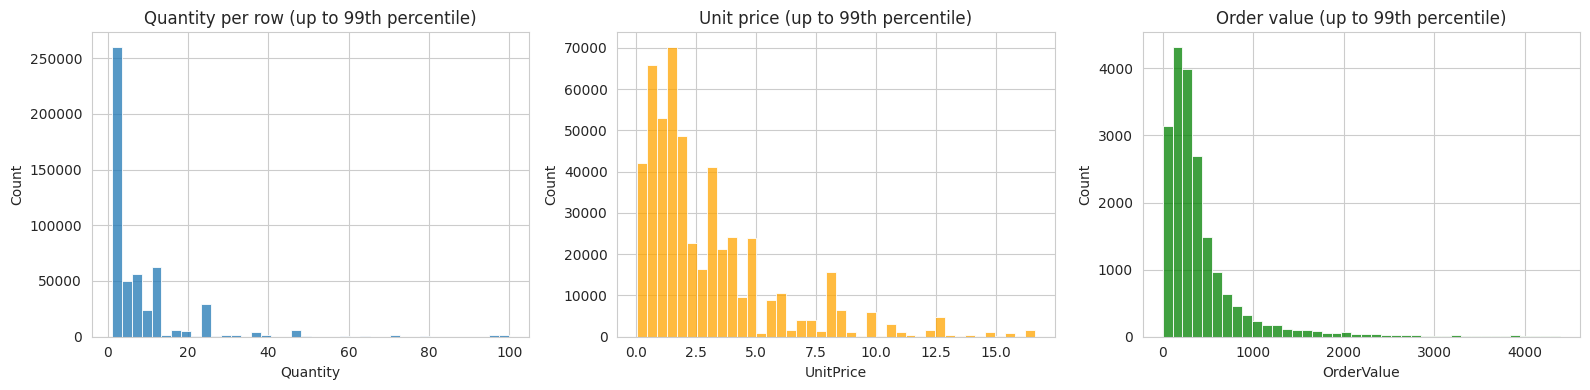

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

q = sales[sales["Quantity"] <= sales["Quantity"].quantile(0.99)]
sns.histplot(q["Quantity"], bins=40, ax=ax[0])
ax[0].set_title("Quantity per row (up to 99th percentile)")

p = sales[sales["UnitPrice"] <= sales["UnitPrice"].quantile(0.99)]
sns.histplot(p["UnitPrice"], bins=40, ax=ax[1], color="orange")
ax[1].set_title("Unit price (up to 99th percentile)")

o = orders[orders["OrderValue"] <= orders["OrderValue"].quantile(0.99)]
sns.histplot(o["OrderValue"], bins=40, ax=ax[2], color="green")
ax[2].set_title("Order value (up to 99th percentile)")

plt.tight_layout()
plt.savefig("figures/01_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**


In [ ]:
# Q5 - average order value
print("Average order value:", round(orders["OrderValue"].mean(), 2))
print("Median order value:", round(orders["OrderValue"].median(), 2))
print("Average units per order:", round(orders["Units"].mean(), 1))

Average order value: 505.85
Median order value: 302.2
Average units per order: 273.4


**Q5 answer:**

### 3.2 Top products (Q1 and Q4, bar charts)

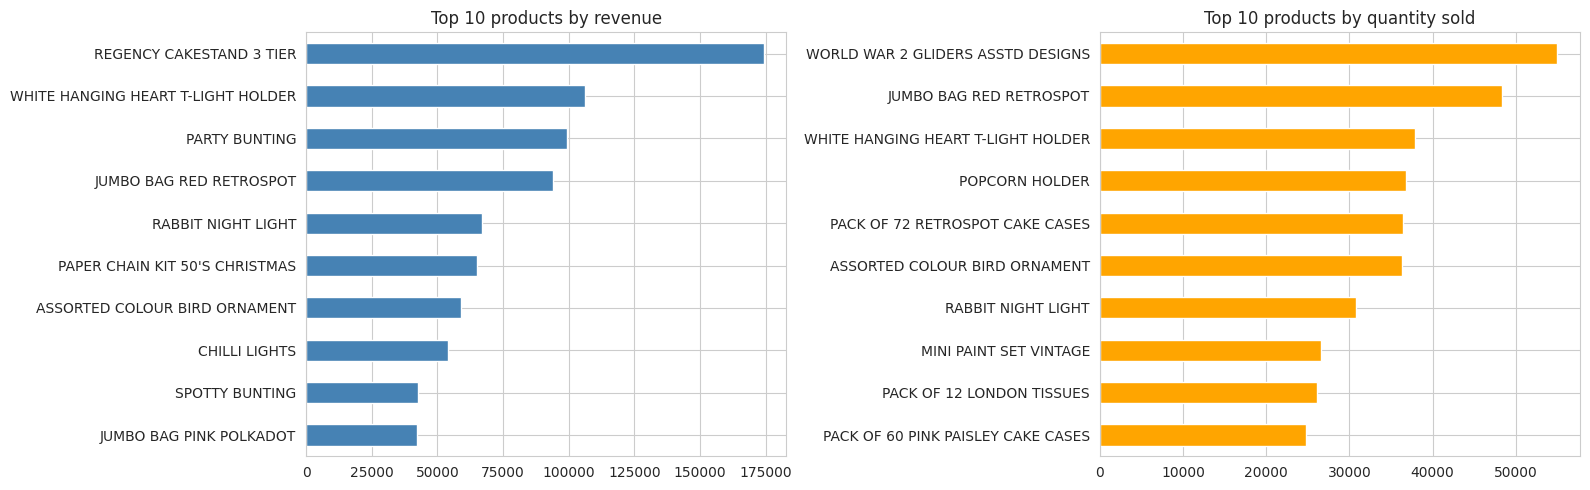

In [ ]:
top_revenue = sales.groupby("Product")["Revenue"].sum().sort_values(ascending=False).head(10)
top_quantity = sales.groupby("Product")["Quantity"].sum().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
top_revenue.sort_values().plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set_title("Top 10 products by revenue")
ax[0].set_ylabel("")

top_quantity.sort_values().plot(kind="barh", ax=ax[1], color="orange")
ax[1].set_title("Top 10 products by quantity sold")
ax[1].set_ylabel("")

plt.tight_layout()
plt.savefig("figures/02_top_products.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**


### 3.3 Revenue by country (Q2, bar chart and box plot)

Share of top country: 84.8 %


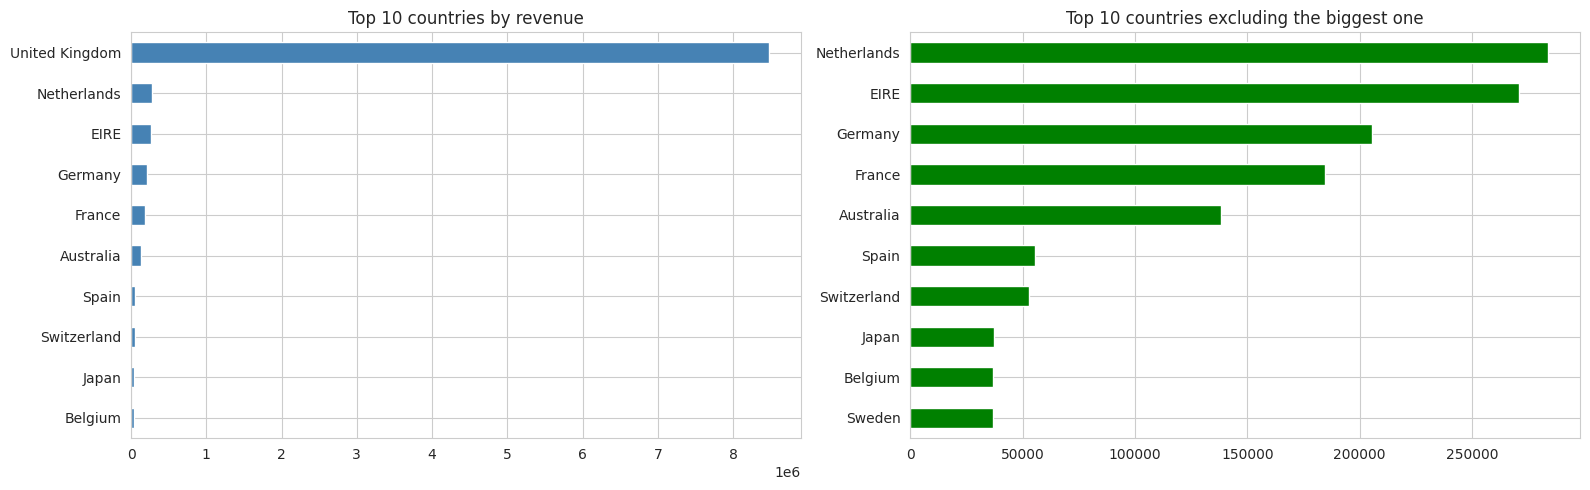

In [ ]:
country_rev = sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
print("Share of top country:", round(country_rev.iloc[0] / country_rev.sum() * 100, 1), "%")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
country_rev.head(10).sort_values().plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set_title("Top 10 countries by revenue")
ax[0].set_ylabel("")

# without the biggest country, to see the other markets properly
country_rev.iloc[1:11].sort_values().plot(kind="barh", ax=ax[1], color="green")
ax[1].set_title("Top 10 countries excluding the biggest one")
ax[1].set_ylabel("")

plt.tight_layout()
plt.savefig("figures/03_country_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

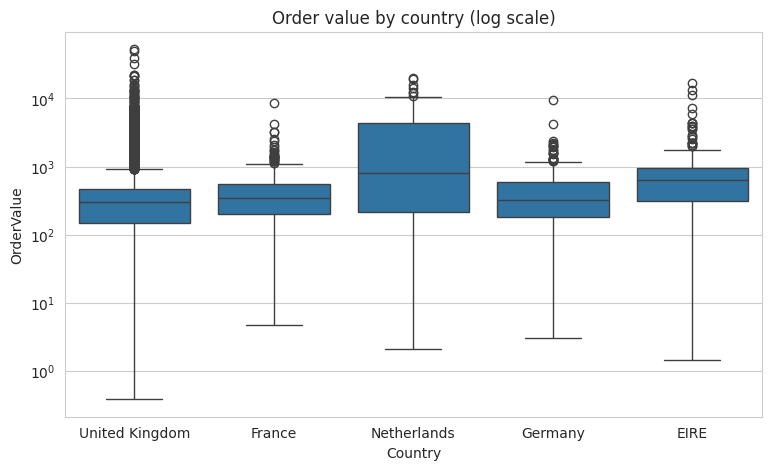

In [ ]:
top5 = country_rev.head(5).index
plt.figure(figsize=(9, 5))
sns.boxplot(data=orders[orders["Country"].isin(top5)], x="Country", y="OrderValue")
plt.yscale("log")
plt.title("Order value by country (log scale)")
plt.savefig("figures/04_boxplot_country.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**



### 3.4 Sales over time (Q3, time series)

Last date in the data: 2011-12-09 12:50:00


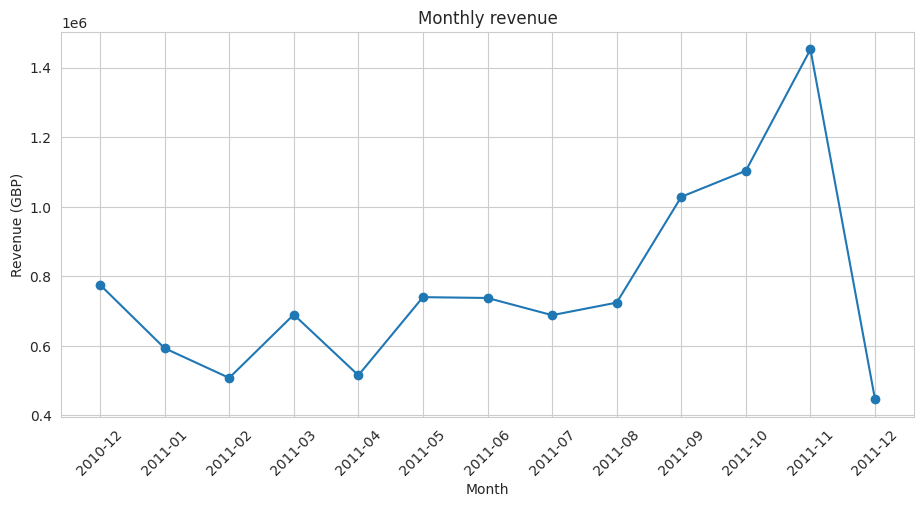

In [ ]:
monthly = sales.groupby("YearMonth")["Revenue"].sum()

plt.figure(figsize=(11, 5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.xticks(rotation=45)
plt.title("Monthly revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (GBP)")
plt.savefig("figures/05_monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

print("Last date in the data:", sales["InvoiceDate"].max())

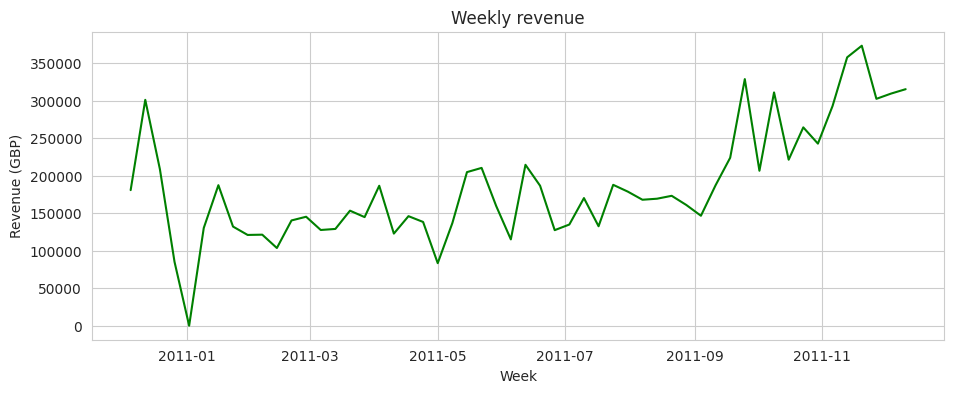

In [ ]:
weekly = sales.set_index("InvoiceDate")["Revenue"].resample("W").sum()

plt.figure(figsize=(11, 4))
plt.plot(weekly.index, weekly.values, color="green")
plt.title("Weekly revenue")
plt.xlabel("Week")
plt.ylabel("Revenue (GBP)")
plt.savefig("figures/06_weekly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**



### 3.5 When do customers order? (2 count plots, box plot, heatmap)

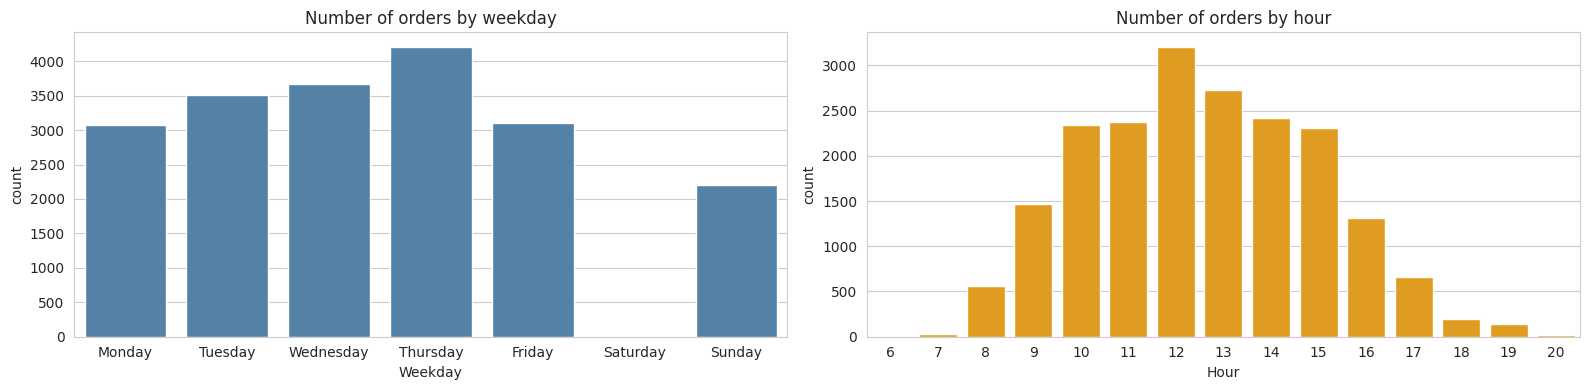

In [ ]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
sns.countplot(data=orders, x="Weekday", order=days, ax=ax[0], color="steelblue")
ax[0].set_title("Number of orders by weekday")

sns.countplot(data=orders, x="Hour", ax=ax[1], color="orange")
ax[1].set_title("Number of orders by hour")

plt.tight_layout()
plt.savefig("figures/07_countplots_time.png", dpi=150, bbox_inches="tight")
plt.show()

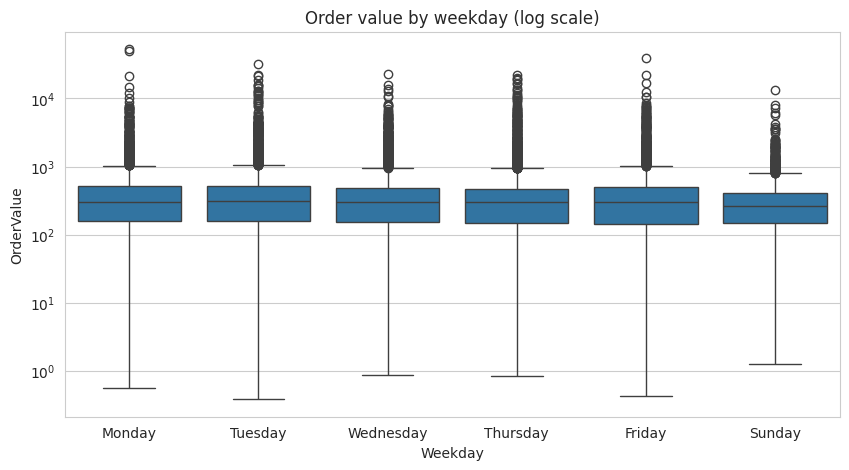

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=orders, x="Weekday", y="OrderValue", order=[d for d in days if d in orders["Weekday"].unique()])
plt.yscale("log")
plt.title("Order value by weekday (log scale)")
plt.savefig("figures/08_boxplot_weekday.png", dpi=150, bbox_inches="tight")
plt.show()

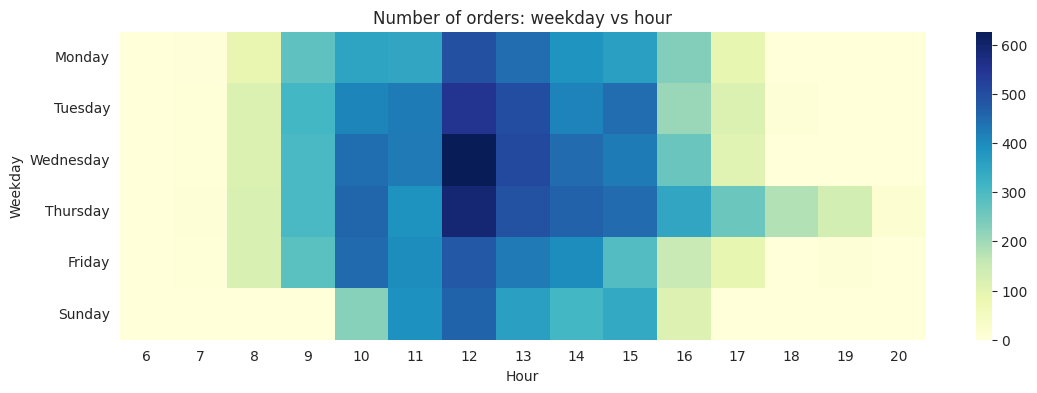

In [ ]:
heat = orders.groupby(["Weekday", "Hour"]).size().unstack(fill_value=0)
heat = heat.reindex([d for d in days if d in heat.index])

plt.figure(figsize=(13, 4))
sns.heatmap(heat, cmap="YlGnBu")
plt.title("Number of orders: weekday vs hour")
plt.savefig("figures/09_heatmap_weekday_hour.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**


### 3.6 Customers (Q6)

Top 20% customers give 73.9 % of revenue


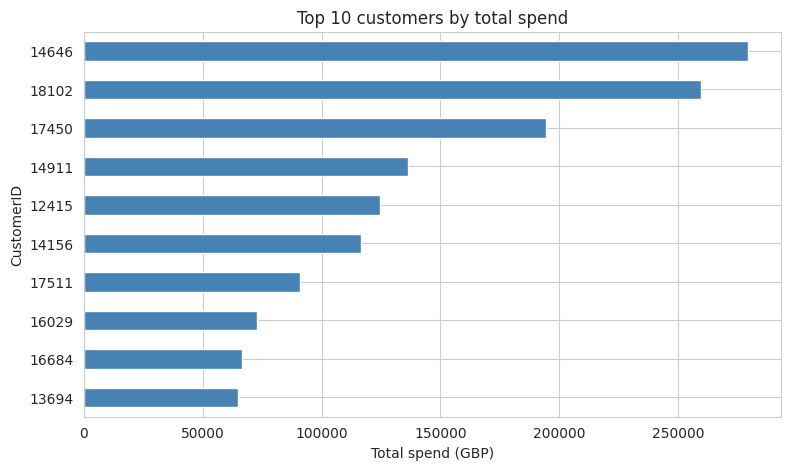

In [ ]:
# RFM table: Recency (days since last order), Frequency (number of orders), Monetary (total spend)
last_date = cust["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = cust.groupby("CustomerID").agg(
    LastOrder=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    Units=("Quantity", "sum")
)
rfm["Recency"] = (last_date - rfm["LastOrder"]).dt.days
rfm["AvgOrderValue"] = rfm["Monetary"] / rfm["Frequency"]

top_customers = rfm["Monetary"].sort_values(ascending=False).head(10)
top_customers.index = top_customers.index.astype(int).astype(str)

top20 = rfm["Monetary"].sort_values(ascending=False).head(int(len(rfm) * 0.2)).sum()
print("Top 20% customers give", round(top20 / rfm["Monetary"].sum() * 100, 1), "% of revenue")

plt.figure(figsize=(9, 5))
top_customers.sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 customers by total spend")
plt.xlabel("Total spend (GBP)")
plt.ylabel("CustomerID")
plt.savefig("figures/10_top_customers.png", dpi=150, bbox_inches="tight")
plt.show()

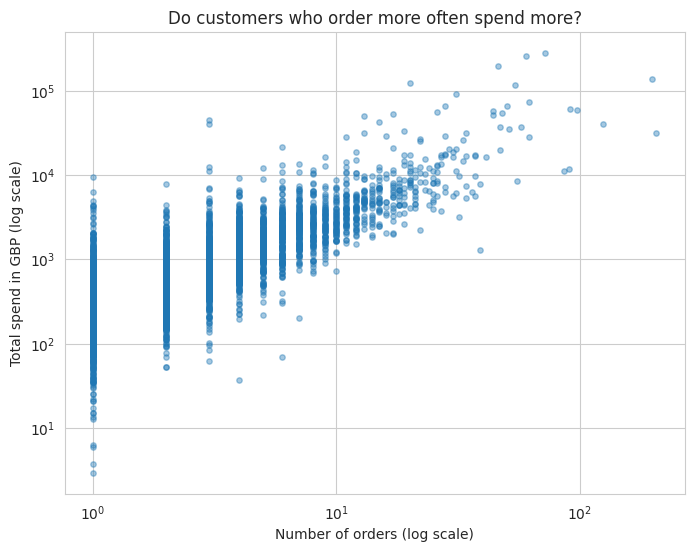

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(rfm["Frequency"], rfm["Monetary"], alpha=0.4, s=15)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of orders (log scale)")
plt.ylabel("Total spend in GBP (log scale)")
plt.title("Do customers who order more often spend more?")
plt.savefig("figures/11_scatter_frequency_spend.png", dpi=150, bbox_inches="tight")
plt.show()

**What I observe:**


,Customers,Revenue,Customers %,Revenue %
Segment,,,,
At risk,555,"960,732.41",12.81,11.31
Lost,1597,"736,833.32",36.86,8.68
Loyal,1443,"6,428,998.75",33.30,75.71
New / Recent,738,"365,009.96",17.03,4.30


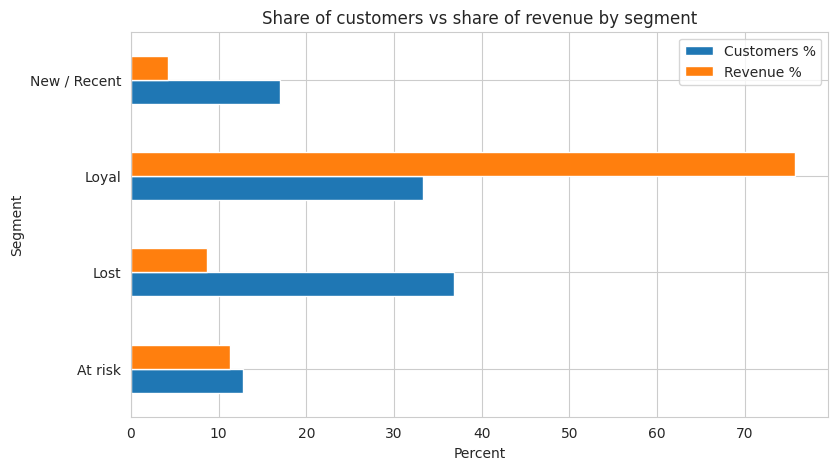

In [ ]:
# Simple customer segments: compare each customer with the median customer
median_recency = rfm["Recency"].median()
median_frequency = rfm["Frequency"].median()

def get_segment(row):
    recent = row["Recency"] <= median_recency       # ordered recently
    frequent = row["Frequency"] > median_frequency  # orders often
    if recent and frequent:
        return "Loyal"
    elif recent:
        return "New / Recent"
    elif frequent:
        return "At risk"
    else:
        return "Lost"

rfm["Segment"] = rfm.apply(get_segment, axis=1)

seg = rfm.groupby("Segment").agg(Customers=("Monetary", "count"), Revenue=("Monetary", "sum"))
seg["Customers %"] = seg["Customers"] / seg["Customers"].sum() * 100
seg["Revenue %"] = seg["Revenue"] / seg["Revenue"].sum() * 100

seg[["Customers %", "Revenue %"]].plot(kind="barh", figsize=(9, 5))
plt.title("Share of customers vs share of revenue by segment")
plt.xlabel("Percent")
plt.savefig("figures/12_customer_segments.png", dpi=150, bbox_inches="tight")
plt.show()

seg

**What I observe:**



### 3.7 Correlation analysis (heatmap)

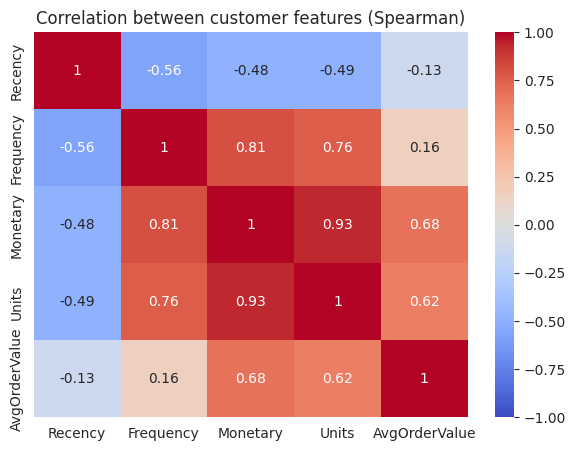

In [ ]:
corr = rfm[["Recency", "Frequency", "Monetary", "Units", "AvgOrderValue"]].corr(method="spearman")

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between customer features (Spearman)")
plt.savefig("figures/13_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

*I used Spearman correlation because the data is very skewed with big outliers.*

**What I observe:**



### 3.8 Price vs quantity (Q10, scatter plot and box plot)

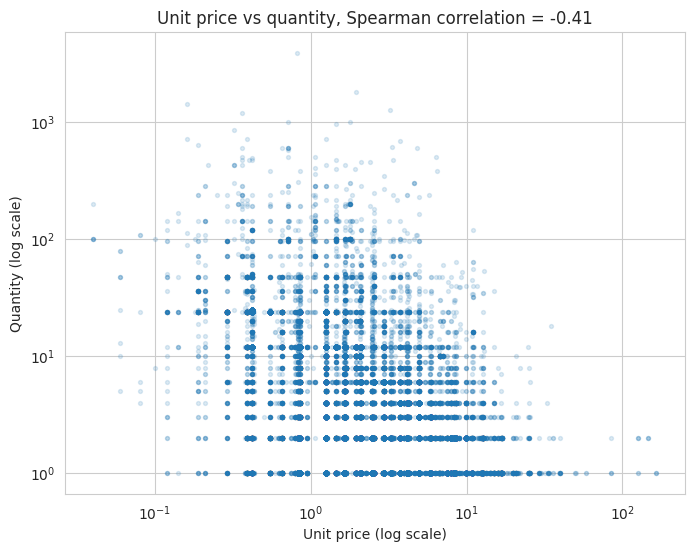

In [ ]:
sample = sales.sample(30000, random_state=1) if len(sales) > 30000 else sales
corr_value = sales["UnitPrice"].corr(sales["Quantity"], method="spearman")

plt.figure(figsize=(8, 6))
plt.scatter(sample["UnitPrice"], sample["Quantity"], alpha=0.15, s=8)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Unit price (log scale)")
plt.ylabel("Quantity (log scale)")
plt.title("Unit price vs quantity, Spearman correlation = " + str(round(corr_value, 2)))
plt.savefig("figures/14_scatter_price_quantity.png", dpi=150, bbox_inches="tight")
plt.show()

PriceBand
Very low    12.00
Low          6.00
Medium       4.00
High         3.00
Very high    2.00
Name: Quantity, dtype: float64

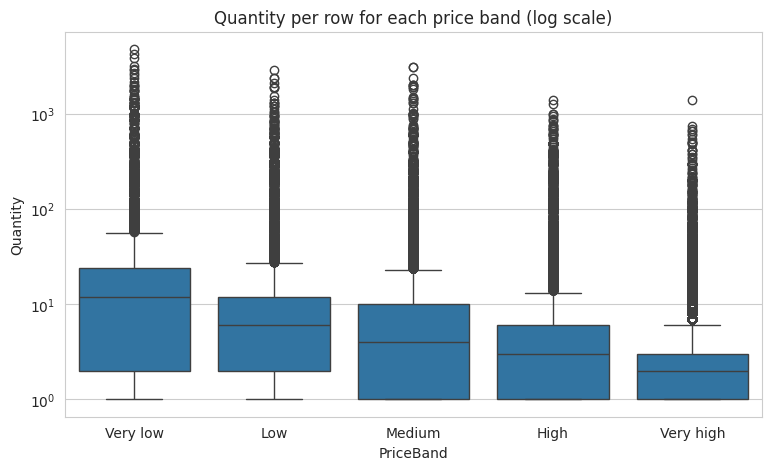

In [ ]:
sales["PriceBand"] = pd.qcut(sales["UnitPrice"], 5, labels=["Very low", "Low", "Medium", "High", "Very high"])

plt.figure(figsize=(9, 5))
sns.boxplot(data=sales, x="PriceBand", y="Quantity")
plt.yscale("log")
plt.title("Quantity per row for each price band (log scale)")
plt.savefig("figures/15_boxplot_priceband.png", dpi=150, bbox_inches="tight")
plt.show()

sales.groupby("PriceBand")["Quantity"].median()

### 3.9 Cancellations (Q8)

Cancelled invoices: 3836 out of 25900
Cancellation rate: 14.8 %
Value of cancelled goods: 893980 GBP


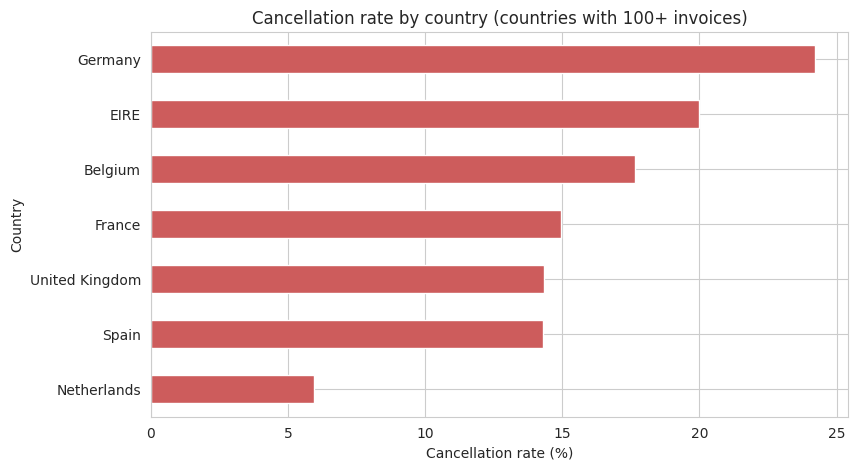

In [ ]:
invoices = df.drop_duplicates("InvoiceNo")
cancel_rate = invoices["IsCancelled"].mean() * 100
print("Cancelled invoices:", invoices["IsCancelled"].sum(), "out of", len(invoices))
print("Cancellation rate:", round(cancel_rate, 1), "%")

cancelled_value = -cancellations["Revenue"].sum()
print("Value of cancelled goods:", round(cancelled_value), "GBP")

by_country = invoices.groupby("Country")["IsCancelled"].agg(["mean", "count"])
by_country = by_country[by_country["count"] >= 100]
by_country = (by_country["mean"] * 100).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
by_country.sort_values().plot(kind="barh", color="indianred")
plt.title("Cancellation rate by country (countries with 100+ invoices)")
plt.xlabel("Cancellation rate (%)")
plt.savefig("figures/16_cancellation_by_country.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.10 Product demand trend (Q9)

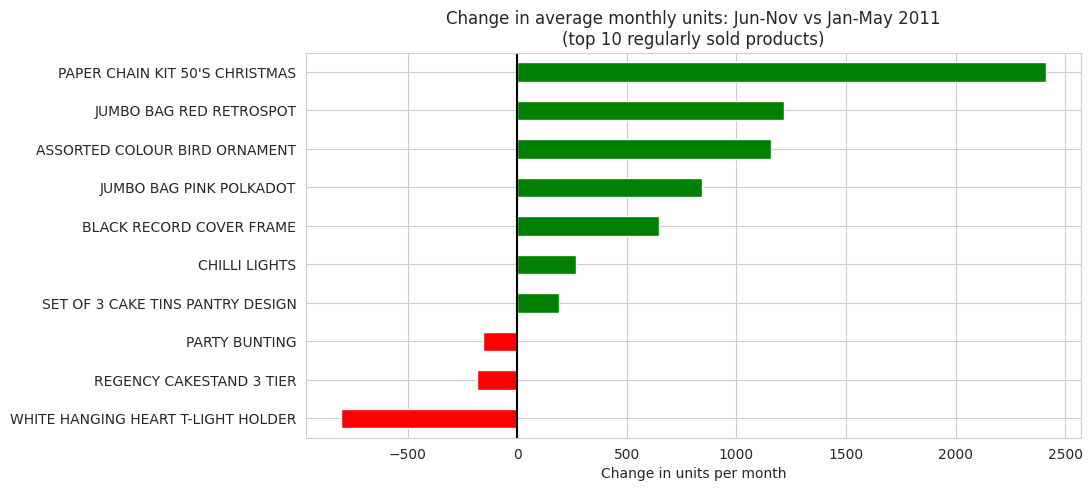

In [ ]:
# only full months (Jan-Nov 2011), because Dec 2010 and Dec 2011 are not complete
months = sales[(sales["YearMonth"] >= "2011-01") & (sales["YearMonth"] <= "2011-11")]

# only products sold in at least 9 of these 11 months, so products launched later in the year are not included
months_sold = months.groupby("Product")["YearMonth"].nunique()
regular_products = months_sold[months_sold >= 9].index

top_products = (sales[sales["Product"].isin(regular_products)]
                .groupby("Product")["Revenue"].sum()
                .sort_values(ascending=False).head(10).index)

monthly_qty = months[months["Product"].isin(top_products)].pivot_table(
    index="YearMonth", columns="Product", values="Quantity", aggfunc="sum").fillna(0)

# average monthly units in Jan-May vs Jun-Nov
first_half = monthly_qty.iloc[:5].mean()
second_half = monthly_qty.iloc[5:].mean()
change = (second_half - first_half).sort_values()

colors = ["red" if x < 0 else "green" for x in change]
plt.figure(figsize=(10, 5))
change.plot(kind="barh", color=colors)
plt.axvline(0, color="black")
plt.title("Change in average monthly units: Jun-Nov vs Jan-May 2011\n(top 10 regularly sold products)")
plt.xlabel("Change in units per month")
plt.ylabel("")
plt.savefig("figures/17_product_trends.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Chart checklist (assignment requirements)

| Required | Where in this notebook |
|---|---|
| 3 histograms | 3.1 (quantity, price, order value) |
| 3 box plots | 3.3 (country), 3.5 (weekday), 3.8 (price band) |
| 3 bar charts | 3.2 (products), 3.3 (countries), 3.6 (customers), 3.9, 3.10 |
| 2 count plots | 3.5 (weekday, hour) |
| 2 scatter plots | 3.6 (frequency vs spend), 3.8 (price vs quantity) |
| 1 correlation heatmap | 3.7 |
| 1 time-series chart | 3.4 (monthly and weekly revenue) |
| 2 additional visualizations | 3.5 (weekday x hour heatmap), 3.6 (customer segments) |

## 5. Insights, Recommendations and Limitations


Key Insights
1. Products: Regency Cakestand 3 Tier generated the highest revenue of approximately £174,157, while World War 2 Gliders had the highest quantity sold, at 54,951 units. This shows that the product generating the most revenue is not necessarily the product sold in the highest quantity.
2. Countries: The United Kingdom contributed 84.8% of total revenue, making it the dominant market. This indicates a strong dependence on the UK customer base.
3. Time / Seasonality: November was the peak sales month, with approximately £1.45 million in sales. However, December 2011 is incomplete, and the dataset covers only about one year, so yearly seasonality cannot be confirmed.
4. Customers: Loyal customers contributed approximately 75.7% of revenue. This highlights the importance of retaining existing customers and encouraging repeat purchases. Customer analysis is limited to records with an available CustomerID.
5. Price and Quantity: The price–quantity correlation was approximately −0.41, indicating a moderate negative relationship: higher-priced products tend to have lower quantities sold. However, correlation does not prove that price alone causes lower sales.
6. Cancellations: Approximately 14.8% of invoices were cancelled. This suggests that cancellations deserve further investigation to identify possible issues with ordering, stock availability, or customer purchasing decisions.
Recommendations
1. Improve inventory planning: Keep popular products, especially Regency Cakestand 3 Tier and World War 2 Gliders, adequately stocked. Prepare inventory in advance of the September–November sales period.
2. Expand international marketing: Since the UK accounts for 84.8% of revenue, explore opportunities in other countries to diversify the customer base and reduce dependence on one market.
3. Strengthen customer retention: Reward loyal customers through loyalty programs, personalized offers, and repeat-purchase discounts. Identify customers whose purchasing activity is declining and consider targeted promotions.
4. Investigate cancellations and pricing: Analyze cancelled invoices to identify recurring patterns, and review pricing strategies for products with lower quantities sold. Use further analysis before making changes to prices or inventory.
Limitations
- The data covers only about one year, so yearly seasonality cannot be confirmed. December 2011 is incomplete.
- Many rows have no CustomerID, so customer analysis covers only known customers.
- The company sells substantially to wholesalers, so the findings may not apply to typical retail businesses.
- This is exploratory analysis. Correlation does not mean causation.